![Banner](../images/08_bayesian_kriging.png)

# Correlation Functions (`correlation_function`)

**Dataset:** mostly synthetic (distances, simulated fields); Jura soil survey (`Data/00_shared/data_geostatistics/jura_data.csv`) for choosing a model from data

**Library:** `geolattice.geostatistics.correlation_function` (module `geolattice.geostatistics.kriging.bayesian_kriging`), with `BayesianKriging` for model choice

**Before this notebook:** [Variogram modelling](../05_01_foundation/05_01_variogram_modeling.ipynb) and [Bayesian kriging](05_08_02_bayesian_kriging.ipynb).

***

## Table of Contents

1. [Overview](#overview)
2. [Theory](#theory)
    - 2.1 [Correlation, covariance and variogram](#correlation-covariance-and-variogram)
    - 2.2 [The models](#the-models)
    - 2.3 [Valid correlation functions: positive definiteness](#valid-correlation-functions-positive-definiteness)
    - 2.4 [Behaviour at the origin and smoothness](#behaviour-at-the-origin-and-smoothness)
    - 2.5 [The Matérn family](#the-matérn-family)
    - 2.6 [The stable family](#the-stable-family)
    - 2.7 [Range parameter and practical range](#range-parameter-and-practical-range)
    - 2.8 [Numerical conditioning](#numerical-conditioning)
3. [Python Setup](#python-setup)
4. [The Models Side by Side](#the-models-side-by-side)
5. [Practical Ranges](#practical-ranges)
6. [Smoothness: Behaviour at the Origin and Sample Paths](#smoothness-behaviour-at-the-origin-and-sample-paths)
7. [The Matérn Family](#the-matérn-family-1)
8. [The Stable Family](#the-stable-family-1)
9. [Positive Definiteness in Practice](#positive-definiteness-in-practice)
10. [Numerical Conditioning](#numerical-conditioning-1)
11. [Simulated Two-Dimensional Fields](#simulated-two-dimensional-fields)
12. [Choosing a Model from Data](#choosing-a-model-from-data)
13. [Summary and Conclusions](#summary-and-conclusions)
    - 13.1 [Choosing a model](#choosing-a-model)
14. [References](#references)

***
## Overview

Every kriging and Gaussian simulation method rests on a model of how correlation decays with distance. `correlation_function(h, model, range_, nu=1.5, alpha=1.0)` returns that correlation, $\rho(h)$, for the six models GeoLattice supports. It is the building block of all the Bayesian kriging classes, and it is useful on its own for building covariance matrices, simulating fields and comparing models.

| Model | `model=` | Shape parameter |
|---|---|---|
| spherical | `"spherical"` | n/a |
| exponential | `"exponential"` | n/a |
| Gaussian | `"gaussian"` | n/a |
| Matérn | `"matern"` | smoothness `nu` |
| cubic | `"cubic"` | n/a |
| stable (powered exponential) | `"stable"` | exponent `alpha` in (0, 2] |

The `range_` parameter follows the `Variogram` convention of each model, so a fitted variogram's parameters can be used directly. In the Bayesian kriging classes, `nu` is passed as the Matérn smoothness or as the stable exponent.

The notebook:

* defines the models and their properties: positive definiteness, smoothness at the origin, practical range and numerical conditioning;
* checks those properties numerically;
* shows what each model's fields look like;
* chooses a model for real data by marginal likelihood.

***
## Theory

### Correlation, covariance and variogram

For a second-order stationary field $Z(\mathbf{x})$ with partial sill $\sigma^2$ and nugget $c_0$:

$$
C(\mathbf{h}) = \sigma^2\rho(\mathbf{h}) + c_0\,\mathbf{1}[\mathbf{h} = \mathbf{0}],
\qquad
\gamma(\mathbf{h}) = c_0 + \sigma^2\bigl(1 - \rho(\mathbf{h})\bigr) \quad (\mathbf{h} \ne \mathbf{0}).
$$

So $\rho(h) = 1 - \gamma(h)$ for a variogram with unit partial sill and no nugget, which is exactly how `correlation_function` evaluates it, from the variogram models in `geolattice.geostatistics.core.variogram_models`. In Bayesian kriging the covariance matrix is $\sigma^2[\mathbf{R}(\phi) + \tau\mathbf{I}]$, with $\mathbf{R}_{ij} = \rho(\lVert\mathbf{x}_i - \mathbf{x}_j\rVert)$ and $\tau = c_0/\sigma^2$.

### The models

With range parameter $a$ and $r = h/a$:

| Model | $\rho(h)$ |
|---|---|
| spherical | $1 - \tfrac32 r + \tfrac12 r^3$ for $r < 1$; $0$ for $r \ge 1$ |
| exponential | $e^{-r}$ |
| Gaussian | $e^{-r^2}$ |
| Matérn | $\dfrac{2^{1-\nu}}{\Gamma(\nu)}\, r^\nu K_\nu(r)$, with $K_\nu$ the modified Bessel function of the second kind |
| cubic | $1 - (7r^2 - 8.75r^3 + 3.5r^5 - 0.75r^7)$ for $r < 1$; $0$ for $r \ge 1$ |
| stable | $e^{-r^\alpha}$, $0 < \alpha \le 2$ |

The spherical and cubic models have **compact support**: the correlation is exactly 0 beyond $a$. The others only decay toward 0.

### Valid correlation functions: positive definiteness

Not every decreasing function is a correlation function. For any locations and weights, the variance of a linear combination must be non-negative:

$$
\operatorname{Var}\Bigl(\sum_i \lambda_i Z(\mathbf{x}_i)\Bigr) = \sigma^2 \sum_{i,j} \lambda_i\lambda_j\, \rho(\mathbf{x}_i - \mathbf{x}_j) \ge 0 .
$$

So $\rho$ must be **positive definite**. By Bochner's theorem this holds exactly when $\rho$ is the Fourier transform of a non-negative spectral density. Validity depends on the dimension:

* all six models are valid in 1, 2 and 3 dimensions;
* the "triangular" function $\max(1 - h/a, 0)$ is valid in 1 dimension only.

An invalid function can make kriging variances negative and Cholesky factorizations fail (Section 9).

### Behaviour at the origin and smoothness

The behaviour of $\rho$ near $h = 0$ sets how rough the field is (Stein, 1999):

* **Linear at the origin** ($1 - \rho(h) \propto h$): exponential, spherical, Matérn $\nu = 1/2$, stable $\alpha = 1$. The field is continuous but **not differentiable**; its sample paths are rough.
* **Parabolic at the origin** ($1 - \rho(h) \propto h^2$): Gaussian, cubic, Matérn $\nu > 1$, stable $\alpha = 2$. The field is mean-square **differentiable**, with smooth sample paths.
* **In general**, a Matérn field is $\lceil\nu\rceil - 1$ times mean-square differentiable, and a stable field with $\alpha < 2$ is not differentiable, with roughness increasing as $\alpha$ decreases.

The behaviour near the origin matters far more for kriging than the shape at large lags (Stein, 1999).

### The Matérn family

The Matérn model has a smoothness parameter $\nu > 0$ and contains the most common models:

* $\nu = 1/2$: the exponential, $\rho = e^{-r}$;
* $\nu = 3/2$: $\rho = (1 + r)\,e^{-r}$;
* $\nu = 5/2$: $\rho = (1 + r + r^2/3)\,e^{-r}$;
* $\nu \to \infty$: the Gaussian. With $a = a_G / (2\sqrt{\nu})$, the Matérn correlation tends to $e^{-(h/a_G)^2}$.

Its spectral density decays like $\lVert\boldsymbol\omega\rVert^{-(2\nu + d)}$, which is why $\nu$ controls the smoothness. Because it spans rough to smooth fields with one extra parameter, it is the default recommendation of much of the modern literature.

### The stable family

$\rho(h) = e^{-(h/a)^\alpha}$, with $0 < \alpha \le 2$:

* $\alpha = 1$ is the exponential and $\alpha = 2$ the Gaussian;
* $\alpha < 1$ gives a sharper drop at the origin and a heavier tail;
* $\alpha > 2$ is **not** positive definite.

In `correlation_function` the exponent is `alpha`, and the Bayesian kriging classes pass their `nu` argument as $\alpha$ when `model="stable"`.

### Range parameter and practical range

The parameter $a$ is not comparable across models. The **practical range** is the distance where $\rho$ falls to 0.05 (where the variogram reaches 95% of its sill):

| Model | Practical range |
|---|---|
| spherical | $0.81\,a$; correlation 0 at $a$ |
| exponential | $\ln 20\,a \approx 3a$ |
| Gaussian | $\sqrt{\ln 20}\,a \approx 1.73a$ |
| stable | $(\ln 20)^{1/\alpha}a \approx 3^{1/\alpha}a$ |
| Matérn | depends on $\nu$ |

When models are compared, their range grids should cover comparable practical ranges.

### Numerical conditioning

Kriging solves systems with the correlation matrix $\mathbf{R}$. Models that are very smooth at the origin (Gaussian, Matérn with large $\nu$) make neighbouring rows of $\mathbf{R}$ nearly identical when points are close relative to the range, so $\mathbf{R}$ becomes **ill-conditioned**: its condition number explodes. GeoLattice adds a tiny diagonal jitter ($10^{-10}$ relative); in practice a small nugget, or a less smooth model, is the robust remedy.

***
## Python Setup

**Installation.** This notebook needs installation option 4 (core, spatial analysis, spatial statistics and geostatistics): `pip install "geolattice[geostats]"`. See "Installation options" in the GeoLattice README.

In [1]:
%matplotlib inline
import time
import warnings

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import logsumexp

import geolattice.geostatistics as pygstat
from geolattice.geostatistics import BayesianKriging, correlation_function

print("pygstat version:", pygstat.__version__)

RESULTS = []
def record(section, status, note=""):
    RESULTS.append({"Feature": section, "Status": status, "Notes": note})
    marker = {"PASS": "✅", "FAIL": "❌", "BLOCKED": "⚠️"}.get(status, "?")
    print(f"{marker} [{status}] {section}  {note}")


MODELS = ["spherical", "exponential", "gaussian", "matern", "cubic", "stable"]
h = np.linspace(0, 4, 801)

pygstat version: 0.3.49


***
## The Models Side by Side

All six models with `range_ = 1`, and the corresponding variograms $\gamma(h) = 1 - \rho(h)$ (unit sill, no nugget). The Matérn model is shown with $\nu = 1.5$ and the stable model with $\alpha = 1.5$.

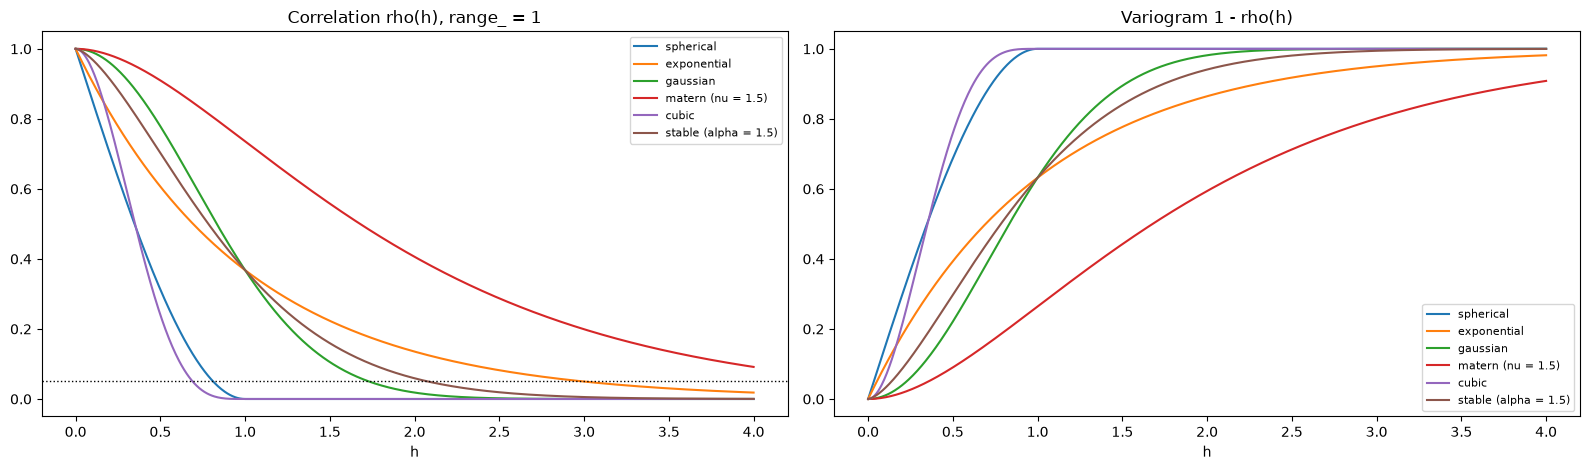

,rho(0),monotone decreasing,rho(10)
spherical,1.0,True,0.0
exponential,1.0,True,0.000045
gaussian,1.0,True,0.0
matern,1.0,True,0.000499
cubic,1.0,True,0.0
stable,1.0,True,0.0


✅ [PASS] rho(0) = 1 and monotone for every model  
✅ [PASS] compact support: spherical and cubic are 0 beyond range_  


In [2]:
def rho(model, hh, a=1.0, nu=1.5, alpha=1.5):
    return correlation_function(hh, model, a, nu=nu, alpha=alpha)


fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
for m in MODELS:
    label = m + (" (nu = 1.5)" if m == "matern" else " (alpha = 1.5)" if m == "stable" else "")
    axes[0].plot(h, rho(m, h), label=label)
    axes[1].plot(h, 1 - rho(m, h), label=label)
axes[0].axhline(0.05, color="k", ls=":", lw=1)
axes[0].set_title("Correlation rho(h), range_ = 1")
axes[1].set_title("Variogram 1 - rho(h)")
for ax in axes:
    ax.set_xlabel("h")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

checks = {m: (rho(m, np.array([0.0]))[0], np.all(np.diff(rho(m, h)) <= 1e-12), rho(m, np.array([10.0]))[0]) for m in MODELS}
display(pd.DataFrame(checks, index=["rho(0)", "monotone decreasing", "rho(10)"]).T)
record("rho(0) = 1 and monotone for every model", "PASS" if all(v[0] == 1 and v[1] for v in checks.values()) else "FAIL")
record("compact support: spherical and cubic are 0 beyond range_",
       "PASS" if np.all(rho("spherical", np.array([1.0, 2.0])) == 0) and np.all(rho("cubic", np.array([1.0, 2.0])) == 0) else "FAIL")

***
## Practical Ranges

The distance where each model's correlation falls below 0.05, found numerically, against the formulas of Section 2.7.

In [3]:
hf = np.linspace(0, 20, 200001)


def practical(model, **kw):
    return hf[np.argmax(correlation_function(hf, model, 1.0, **kw) < 0.05)]


rows = [
    {"model": "spherical", "numerical": practical("spherical"), "formula": 0.81},
    {"model": "exponential", "numerical": practical("exponential"), "formula": np.log(20)},
    {"model": "gaussian", "numerical": practical("gaussian"), "formula": np.sqrt(np.log(20))},
    {"model": "cubic", "numerical": practical("cubic"), "formula": np.nan},
]
for a_ in [0.5, 1.0, 1.5, 2.0]:
    rows.append({"model": f"stable, alpha = {a_}", "numerical": practical("stable", alpha=a_), "formula": np.log(20) ** (1 / a_)})
for nu in [0.5, 1.5, 2.5, 5.0]:
    rows.append({"model": f"matern, nu = {nu}", "numerical": practical("matern", nu=nu), "formula": np.log(20) if nu == 0.5 else np.nan})
pr = pd.DataFrame(rows).set_index("model")
display(pr.round(3))
ok = pr.dropna()
record("practical ranges match the formulas", "PASS" if np.allclose(ok["numerical"], ok["formula"], atol=0.01) else "FAIL",
       f"max error {np.abs(ok['numerical'] - ok['formula']).max():.3f}")

,numerical,formula
model,,
spherical,0.812,0.810
exponential,2.996,2.996
gaussian,1.731,1.731
cubic,0.690,NaN
"stable, alpha = 0.5",8.974,8.974
"stable, alpha = 1.0",2.996,2.996
"stable, alpha = 1.5",2.078,2.078
"stable, alpha = 2.0",1.731,1.731
"matern, nu = 0.5",2.996,2.996


✅ [PASS] practical ranges match the formulas  max error 0.001


The numerical practical ranges match the formulas to within 0.002. Spherical is 0.812 against the rounded 0.81, and the rest are exact with $\ln 20 \approx 2.996$. The cubic model reaches 0.05 at $0.69a$.

The Matérn row is the one to remember. With the same `range_ = 1`, the practical range is 3.0 for $\nu = 0.5$, 4.74 for $\nu = 1.5$, 5.92 for $\nu = 2.5$ and 8.09 for $\nu = 5$. The stable model with $\alpha = 0.5$ reaches 8.97. A `range_` value therefore means something different in every model, so range grids and priors should be set in practical-range units, as Section 12 does.

***
## Smoothness: Behaviour at the Origin and Sample Paths

Close to $h = 0$, $1 - \rho(h)$ grows linearly for the exponential and spherical models and quadratically for the Gaussian and cubic. On log-log axes the slope is the power: 1 for linear, 2 for parabolic. One-dimensional Gaussian fields simulated with each model (the same random numbers, practical range 1) show what that means for the data.

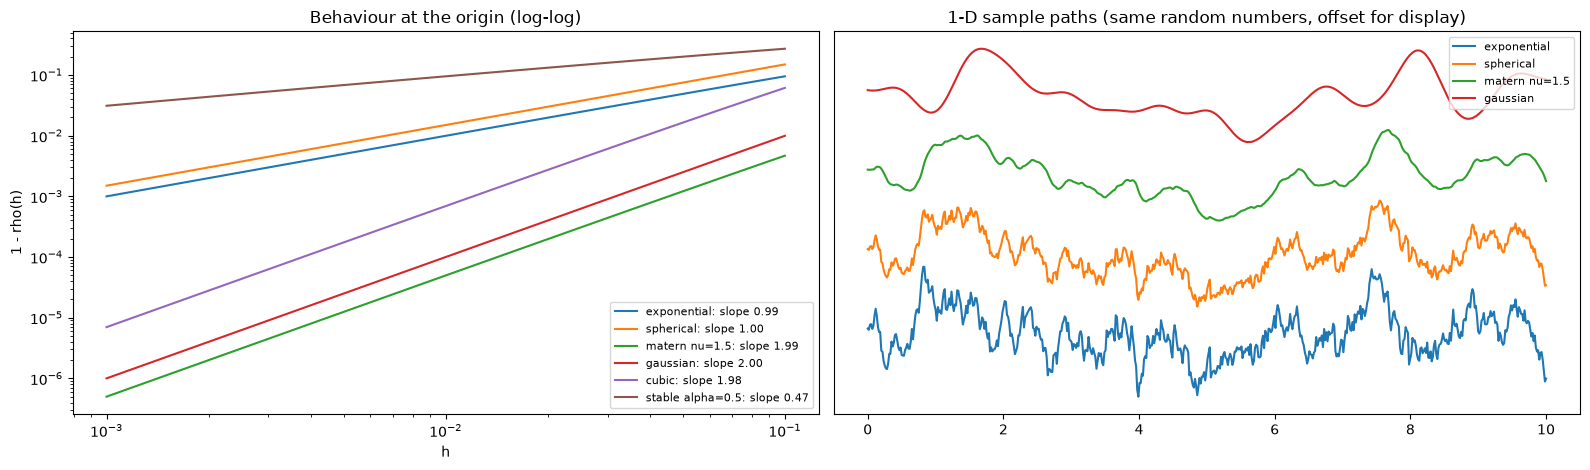

,log-log slope near 0
exponential,0.99
spherical,1.00
matern nu=1.5,1.99
gaussian,2.00
cubic,1.98
stable alpha=0.5,0.47


✅ [PASS] exponential slope ~1, gaussian slope ~2  exponential 0.99, gaussian 2.00


In [4]:
hs = np.geomspace(1e-3, 1e-1, 50)
slopes = {}
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
for m, kw in [("exponential", {}), ("spherical", {}), ("matern", dict(nu=1.5)), ("gaussian", {}), ("cubic", {}),
              ("stable", dict(alpha=0.5))]:
    v = 1 - correlation_function(hs, m, 1.0, **kw)
    slope = np.polyfit(np.log(hs), np.log(v), 1)[0]
    label = m + (" nu=1.5" if m == "matern" else " alpha=0.5" if m == "stable" else "")
    slopes[label] = slope
    axes[0].loglog(hs, v, label=f"{label}: slope {slope:.2f}")
axes[0].set_xlabel("h")
axes[0].set_ylabel("1 - rho(h)")
axes[0].set_title("Behaviour at the origin (log-log)")
axes[0].legend(fontsize=8)

x = np.linspace(0, 10, 600)
d = np.abs(x[:, None] - x[None, :])
eps = np.random.default_rng(0).standard_normal(len(x))
scale = {"exponential": 1 / 3, "spherical": 1 / 0.81, "gaussian": 1 / np.sqrt(3), "matern": 1 / 3}
for i, (m, kw) in enumerate([("exponential", {}), ("spherical", {}), ("matern", dict(nu=1.5)), ("gaussian", {})]):
    R = correlation_function(d, m, scale[m], **kw)
    L = np.linalg.cholesky(R + 1e-8 * np.eye(len(x)))
    axes[1].plot(x, L @ eps + 3 * i, label=m + (" nu=1.5" if m == "matern" else ""))
axes[1].set_title("1-D sample paths (same random numbers, offset for display)")
axes[1].set_yticks([])
axes[1].legend(fontsize=8, loc="upper right")
plt.tight_layout()
plt.show()
display(pd.Series(slopes, name="log-log slope near 0").round(2).to_frame())
record("exponential slope ~1, gaussian slope ~2", "PASS" if abs(slopes["exponential"] - 1) < 0.05 and abs(slopes["gaussian"] - 2) < 0.05 else "FAIL",
       f"exponential {slopes['exponential']:.2f}, gaussian {slopes['gaussian']:.2f}")

The log-log slopes confirm the classification of Section 2.4:

* exponential (0.99) and spherical (1.00) are linear at the origin;
* Matérn $\nu = 1.5$ (1.99), Gaussian (2.00) and cubic (1.98) are parabolic;
* stable $\alpha = 0.5$ has slope 0.47, which is $\alpha$ itself, so it is rougher than the exponential.

The sample paths use the same random numbers and the same practical range, so they differ only in texture. The exponential and spherical paths are jagged at every scale. Matérn $\nu = 1.5$ is smooth with visible changes of slope. The Gaussian path is very smooth, which is rarely realistic for soil or ore data.

***
## The Matérn Family

The closed forms of Section 2.5 for $\nu = 0.5, 1.5, 2.5$ are checked, then the limit to the Gaussian with the rescaled range $a = a_G/(2\sqrt{\nu})$.

max |matern - closed form|: {0.5: '4.4e-16', 1.5: '5.6e-16', 2.5: '6.7e-16'}
✅ [PASS] Matern closed forms for nu = 0.5, 1.5, 2.5  max error 6.7e-16


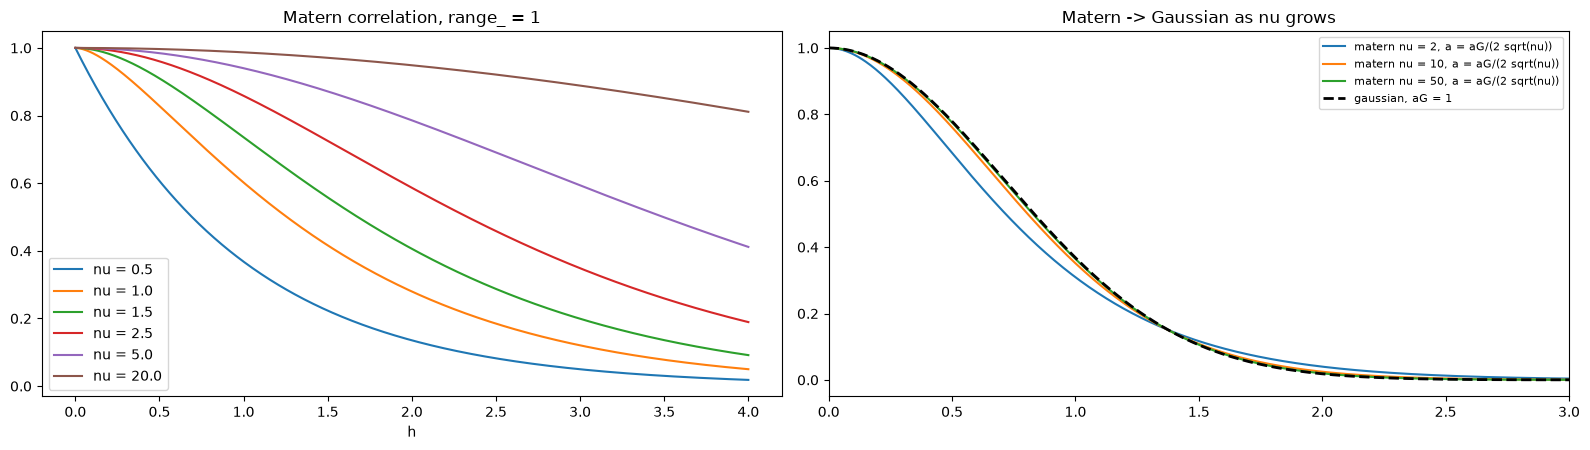

max |matern - gaussian| for nu = 1, 2, 5, 10, 20, 50: [0.1783 0.1019 0.0443 0.0227 0.0114 0.0046]
✅ [PASS] Matern approaches the Gaussian as nu grows  max difference 0.178 (nu = 1) -> 0.0046 (nu = 50)


In [5]:
r_ = h
closed = {0.5: np.exp(-r_), 1.5: (1 + r_) * np.exp(-r_), 2.5: (1 + r_ + r_ ** 2 / 3) * np.exp(-r_)}
err = {nu: np.abs(correlation_function(h, "matern", 1.0, nu=nu) - f).max() for nu, f in closed.items()}
print("max |matern - closed form|:", {k: f"{v:.1e}" for k, v in err.items()})
record("Matern closed forms for nu = 0.5, 1.5, 2.5", "PASS" if max(err.values()) < 1e-6 else "FAIL", f"max error {max(err.values()):.1e}")

aG = 1.0
fig, axes = plt.subplots(1, 2, figsize=(16, 4.6))
for nu in [0.5, 1.0, 1.5, 2.5, 5.0, 20.0]:
    axes[0].plot(h, correlation_function(h, "matern", 1.0, nu=nu), label=f"nu = {nu}")
axes[0].set_title("Matern correlation, range_ = 1")
axes[0].set_xlabel("h")
axes[0].legend()
dist_to_gauss = []
for nu in [1, 2, 5, 10, 20, 50]:
    m_ = correlation_function(h, "matern", aG / (2 * np.sqrt(nu)), nu=nu)
    dist_to_gauss.append(np.abs(m_ - correlation_function(h, "gaussian", aG)).max())
    if nu in (2, 10, 50):
        axes[1].plot(h, m_, label=f"matern nu = {nu}, a = aG/(2 sqrt(nu))")
axes[1].plot(h, correlation_function(h, "gaussian", aG), "k--", lw=2, label="gaussian, aG = 1")
axes[1].set_xlim(0, 3)
axes[1].set_title("Matern -> Gaussian as nu grows")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()
print("max |matern - gaussian| for nu = 1, 2, 5, 10, 20, 50:", np.round(dist_to_gauss, 4))
record("Matern approaches the Gaussian as nu grows", "PASS" if dist_to_gauss[-1] < 0.01 and dist_to_gauss[-1] < dist_to_gauss[0] else "FAIL",
       f"max difference {dist_to_gauss[0]:.3f} (nu = 1) -> {dist_to_gauss[-1]:.4f} (nu = 50)")

***
## The Stable Family

$\alpha$ from 0.5 to 2: $\alpha = 1$ is the exponential and $\alpha = 2$ the Gaussian. An exponent above 2 is rejected because it is not positive definite.

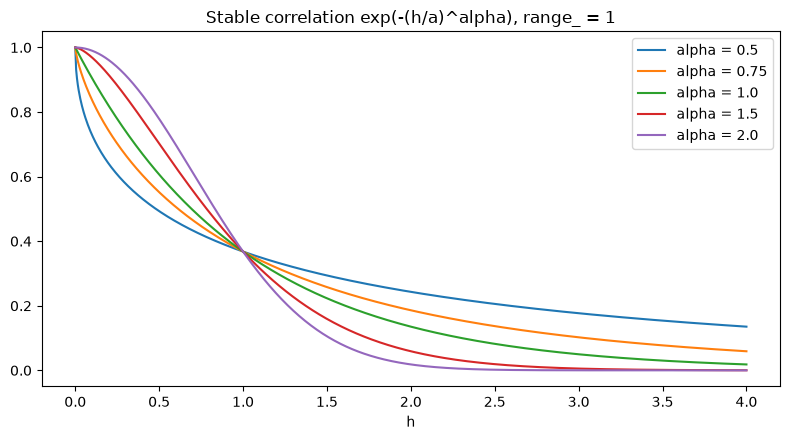

alpha = 2.5: stable exponent alpha must be in (0, 2]
✅ [PASS] stable alpha = 1 / 2 equal exponential / gaussian; alpha > 2 rejected  errors 0.0e+00, 0.0e+00


In [6]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for a_ in [0.5, 0.75, 1.0, 1.5, 2.0]:
    ax.plot(h, correlation_function(h, "stable", 1.0, alpha=a_), label=f"alpha = {a_}")
ax.set_xlabel("h")
ax.set_title("Stable correlation exp(-(h/a)^alpha), range_ = 1")
ax.legend()
plt.tight_layout()
plt.show()
e1 = np.abs(correlation_function(h, "stable", 1.0, alpha=1.0) - correlation_function(h, "exponential", 1.0)).max()
e2 = np.abs(correlation_function(h, "stable", 1.0, alpha=2.0) - correlation_function(h, "gaussian", 1.0)).max()
try:
    correlation_function(h, "stable", 1.0, alpha=2.5)
    rejected = False
except ValueError as e:
    rejected = True
    print("alpha = 2.5:", e)
record("stable alpha = 1 / 2 equal exponential / gaussian; alpha > 2 rejected",
       "PASS" if e1 < 1e-12 and e2 < 1e-12 and rejected else "FAIL", f"errors {e1:.1e}, {e2:.1e}")

***
## Positive Definiteness in Practice

The smallest eigenvalue of the correlation matrix on 400 random points in the unit square, for each model with practical range about 0.5. A valid model gives eigenvalues $\ge 0$ (up to rounding). For contrast, two **invalid** functions:

* the triangular function $\max(1 - h/a, 0)$, valid only in one dimension;
* a stable model with $\alpha = 2.5$, built by hand.

In [7]:
pts = np.random.default_rng(1).uniform(0, 1, (400, 2))
D = np.sqrt(((pts[:, None] - pts[None]) ** 2).sum(-1))
mats = {"spherical": correlation_function(D, "spherical", 0.5 / 0.81),
        "exponential": correlation_function(D, "exponential", 0.5 / 3),
        "gaussian": correlation_function(D, "gaussian", 0.5 / np.sqrt(3)),
        "matern nu=1.5": correlation_function(D, "matern", 0.5 / 4.75, nu=1.5),
        "cubic": correlation_function(D, "cubic", 0.5),
        "stable alpha=1.5": correlation_function(D, "stable", 0.5 / 3 ** (1 / 1.5), alpha=1.5),
        "INVALID triangular (1-D only)": np.maximum(1 - D / 0.5, 0.0),
        "INVALID stable alpha=2.5": np.exp(-(D / 0.3) ** 2.5)}
eig = pd.Series({k: np.linalg.eigvalsh(v).min() for k, v in mats.items()}, name="smallest eigenvalue")
display(eig.to_frame())
valid_ok = all(eig[k] > -1e-8 for k in mats if not k.startswith("INVALID"))
invalid_neg = all(eig[k] < -1e-6 for k in mats if k.startswith("INVALID"))
record("valid models positive semi-definite, invalid ones not", "PASS" if valid_ok and invalid_neg else "FAIL")

,smallest eigenvalue
spherical,5.313998e-03
exponential,1.311379e-02
gaussian,-1.319614e-14
matern nu=1.5,4.981923e-05
cubic,1.243578e-05
stable alpha=1.5,7.429634e-04
INVALID triangular (1-D only),-4.238231e-01
INVALID stable alpha=2.5,-1.023516e+00


✅ [PASS] valid models positive semi-definite, invalid ones not  


All six GeoLattice models give a non-negative smallest eigenvalue. The values run from $1.3 \times 10^{-2}$ (exponential) down to $5 \times 10^{-5}$ (Matérn) and $-1.3 \times 10^{-14}$ for the Gaussian. The Gaussian value is rounding error: the matrix is valid but numerically singular, which Section 10 looks at.

The two invalid functions give clearly negative eigenvalues: −0.42 for the triangular function, which is valid only in one dimension, and −1.02 for the stable model with $\alpha = 2.5$. Kriging with either matrix can produce negative variances, and Cholesky-based simulation fails. This is why `correlation_function` rejects $\alpha > 2$.

***
## Numerical Conditioning

The condition number of $\mathbf{R}$ for 300 random points in the unit square, as the practical range grows from 0.1 to 2, for a rough model (exponential), a moderately smooth one (Matérn $\nu = 1.5$) and a very smooth one (Gaussian). Adding a relative nugget of 0.01 shows the usual remedy.

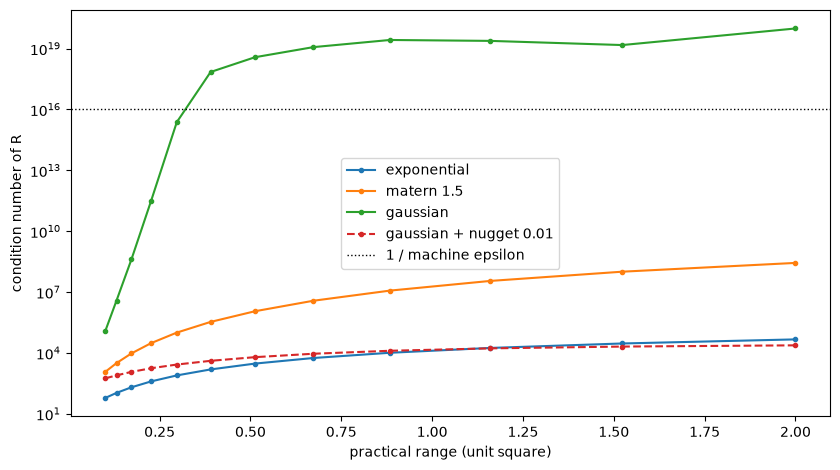

,exponential,exponential + nugget 0.01,matern 1.5,matern 1.5 + nugget 0.01,gaussian,gaussian + nugget 0.01
practical range,,,,,,
0.100000,6.1e+01,5.2e+01,1.2e+03,3.3e+02,1.1e+05,5.6e+02
0.390281,1.5e+03,9.6e+02,3.4e+05,3.2e+03,7.0e+17,4.1e+03
2.000000,4.7e+04,1.1e+04,2.7e+08,2.0e+04,9.7e+19,2.4e+04


In [8]:
pts = np.random.default_rng(2).uniform(0, 1, (300, 2))
D = np.sqrt(((pts[:, None] - pts[None]) ** 2).sum(-1))
prs = np.geomspace(0.1, 2.0, 12)
rows = []
for pr_ in prs:
    row = {"practical range": pr_}
    for name, model, a_fac, kw in [("exponential", "exponential", 1 / 3, {}), ("matern 1.5", "matern", 1 / 4.75, dict(nu=1.5)),
                                   ("gaussian", "gaussian", 1 / np.sqrt(3), {})]:
        R = correlation_function(D, model, pr_ * a_fac, **kw)
        row[name] = np.linalg.cond(R)
        row[name + " + nugget 0.01"] = np.linalg.cond(R + 0.01 * np.eye(len(D)))
    rows.append(row)
cond = pd.DataFrame(rows).set_index("practical range")
fig, ax = plt.subplots(figsize=(8.5, 4.8))
for col, st in [("exponential", "-"), ("matern 1.5", "-"), ("gaussian", "-"), ("gaussian + nugget 0.01", "--")]:
    ax.semilogy(cond.index, cond[col], st, marker="o", ms=3, label=col)
ax.axhline(1e16, color="k", ls=":", lw=1, label="1 / machine epsilon")
ax.set_xlabel("practical range (unit square)")
ax.set_ylabel("condition number of R")
ax.legend()
plt.tight_layout()
plt.show()
display(cond.iloc[[0, 5, -1]].apply(lambda c: c.map(lambda v: f"{v:.1e}")))

The smoothness of the model, more than the range, drives conditioning:

* **Practical range 0.1.** The condition numbers are 61 (exponential), $1.2 \times 10^3$ (Matérn 1.5) and $1.1 \times 10^5$ (Gaussian).
* **Practical range 0.39.** The Gaussian matrix reaches $7 \times 10^{17}$. That is beyond $1/\varepsilon \approx 10^{16}$, so its solution has no correct digits.
* **Practical range 2.** The values are $4.7 \times 10^4$ (exponential), $2.7 \times 10^8$ (Matérn) and $9.7 \times 10^{19}$ (Gaussian).

A relative nugget of 0.01 brings the Gaussian down to $4.1 \times 10^3$ and $2.4 \times 10^4$ for the last two ranges, similar to the exponential. A Gaussian model therefore needs a nugget in practice, even when the data seem to have none.

***
## Simulated Two-Dimensional Fields

`correlation_function` is all that is needed to simulate a Gaussian field: build $\mathbf{R}$, factor it, and multiply white noise. Fields on a 60 × 60 grid, with the same random numbers and a practical range of 0.3 for every model, show the texture each model implies.

6 fields of 3600 nodes in 3.9 s


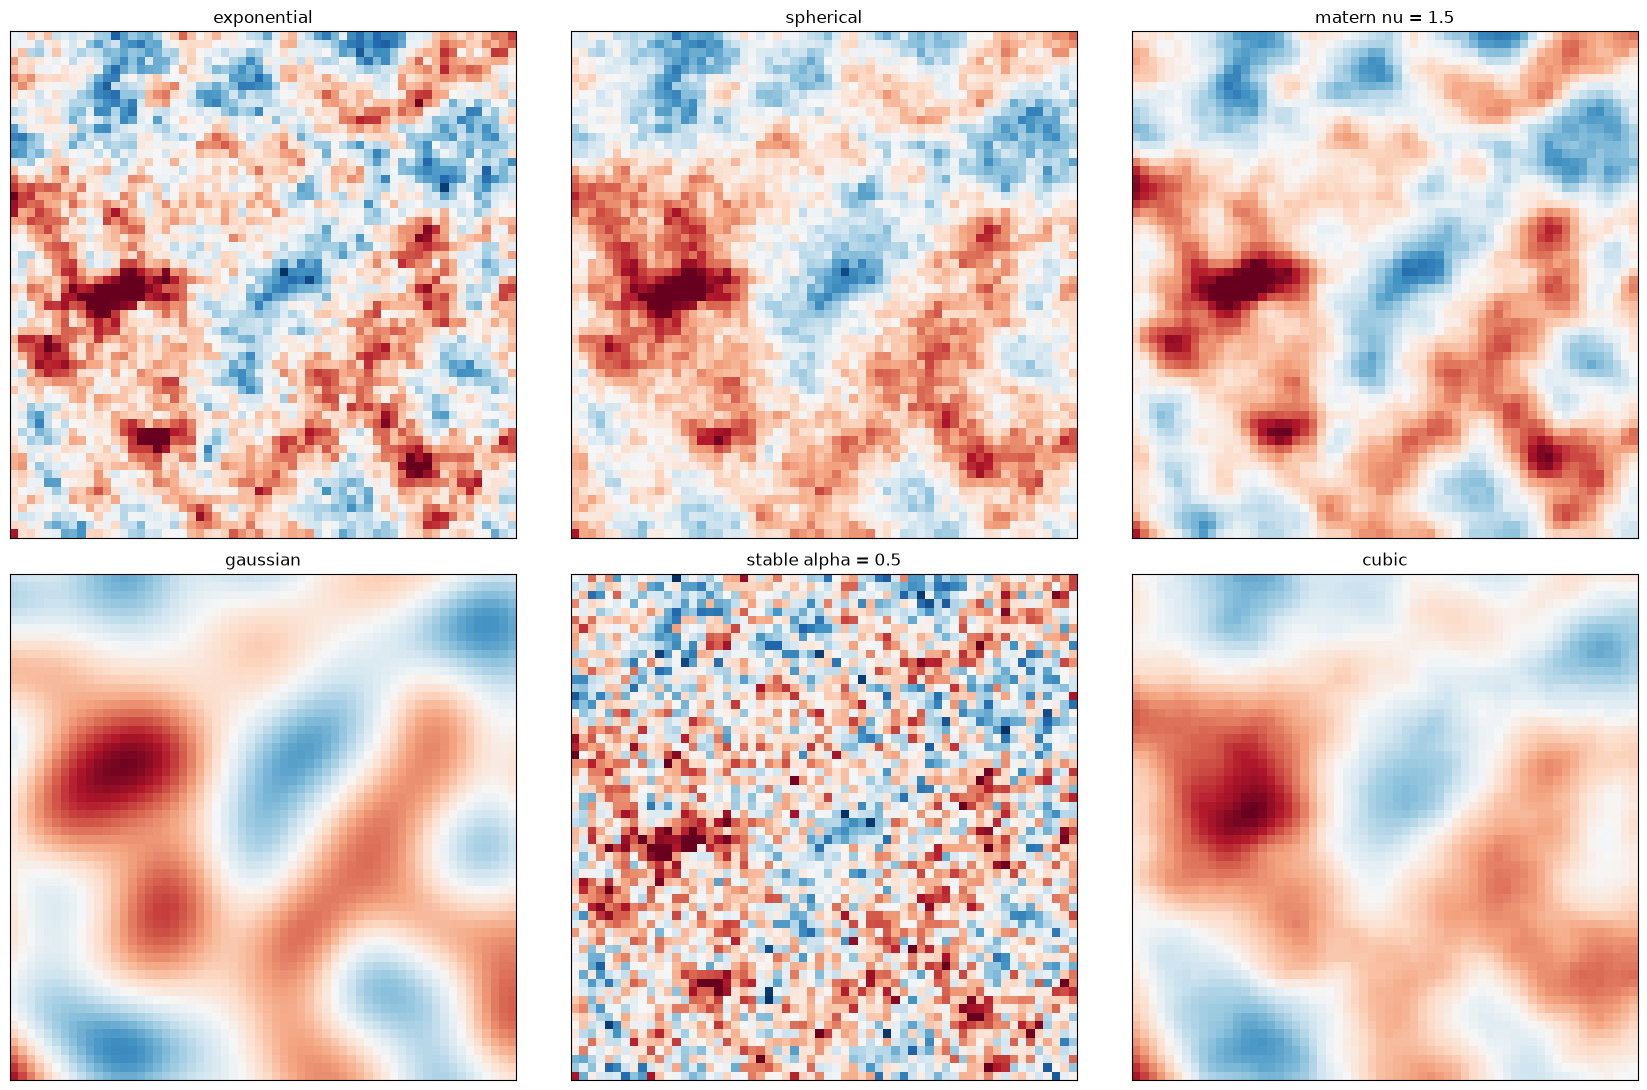

In [9]:
n = 60
gx, gy = np.meshgrid(np.linspace(0, 1, n), np.linspace(0, 1, n))
P = np.column_stack([gx.ravel(), gy.ravel()])
Dg = np.sqrt(((P[:, None] - P[None]) ** 2).sum(-1))
eps = np.random.default_rng(3).standard_normal(len(P))
specs = [("exponential", "exponential", 0.3 / 3, {}), ("spherical", "spherical", 0.3 / 0.81, {}),
         ("matern nu = 1.5", "matern", 0.3 / 4.75, dict(nu=1.5)), ("gaussian", "gaussian", 0.3 / np.sqrt(3), {}),
         ("stable alpha = 0.5", "stable", 0.3 / 9.0, dict(alpha=0.5)), ("cubic", "cubic", 0.3 / 0.6, {})]
fig, axes = plt.subplots(2, 3, figsize=(17, 11))
t0 = time.perf_counter()
for ax, (title, model, a_, kw) in zip(axes.flat, specs):
    R = correlation_function(Dg, model, a_, **kw)
    L = np.linalg.cholesky(R + 1e-6 * np.eye(len(P)))
    im = ax.imshow((L @ eps).reshape(n, n), origin="lower", cmap="RdBu_r", vmin=-2.5, vmax=2.5)
    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])
print(f"6 fields of {len(P)} nodes in {time.perf_counter() - t0:.1f} s")
plt.tight_layout()
plt.show()

All six fields share the same random numbers and the same practical range, so their large features sit in the same places. The differences are in the short-scale texture:

* the exponential and stable $\alpha = 0.5$ fields are speckled, and the stable one has the most fine detail;
* the spherical field is also rough at short scale;
* the Matérn $\nu = 1.5$ and cubic fields show smooth blobs;
* the Gaussian field is the smoothest.

Each field took about 0.7 s, because a dense Cholesky factorization costs $O(n^3)$. For grids much beyond a few thousand nodes, use the sequential simulators of Section 05_07 instead.

***
## Choosing a Model from Data

Which correlation model fits a real variable? `BayesianKriging` computes the marginal likelihood of each model, integrated over a grid of ranges and nugget ratios. The sum over the grid, weighted by the prior, is the model **evidence**, and differences of log evidence are log Bayes factors. For log-cadmium in the Jura, the candidates are:

* the spherical, exponential, Gaussian and cubic models;
* Matérn with $\nu \in \{1, 1.5, 2.5\}$;
* stable with $\alpha \in \{0.25, 0.5, 0.75, 1.5\}$.

Matérn $\nu = 0.5$ and stable $\alpha = 1$ are left out because they are the exponential model; including them would count the same model three times in the posterior probabilities. Each range grid covers practical ranges from 0.1 to 4 km, and all models share the same flat trend and $\sigma^2$ priors, so their evidences are comparable. The model prior is uniform over the list.

In [10]:
DATA = "../../../../Data/00_shared/data_geostatistics/"
jura = pd.read_csv(DATA + "jura_data.csv", index_col=0)
xyj = jura[["Xloc", "Yloc"]].to_numpy(float)
zj = np.log(jura["Cd"].to_numpy(float))
PRAC = np.geomspace(0.1, 4.0, 25)
NUG = [0.0, 0.1, 0.25, 0.5, 1.0]
candidates = [("spherical", "spherical", 1.5, 1 / 0.81), ("exponential", "exponential", 1.5, 1 / 3),
              ("gaussian", "gaussian", 1.5, 1 / np.sqrt(3)), ("cubic", "cubic", 1.5, 1 / 0.6)]
for nu in [1.0, 1.5, 2.5]:
    candidates.append((f"matern nu = {nu}", "matern", nu, 1 / practical("matern", nu=nu)))
for a_ in [0.25, 0.5, 0.75, 1.5]:
    candidates.append((f"stable alpha = {a_}", "stable", a_, 1 / np.log(20) ** (1 / a_)))
rows = []
for name, model, shape, fac in candidates:
    m = BayesianKriging(model, nu=shape, range_grid=PRAC * fac, nugget_grid=NUG).fit(xyj, zj)
    p_ = m.posterior_
    rows.append({"model": name, "log evidence": logsumexp(p_.log_marginal + p_.log_prior),
                 "posterior mean practical range (km)": float((p_.weight * p_.range).sum() / fac),
                 "posterior mean nugget ratio": float((p_.weight * p_.nugget_ratio).sum())})
ev = pd.DataFrame(rows).set_index("model")
ev["log Bayes factor vs best"] = ev["log evidence"] - ev["log evidence"].max()
ev["posterior probability"] = np.exp(ev["log Bayes factor vs best"]) / np.exp(ev["log Bayes factor vs best"]).sum()
display(ev.sort_values("log evidence", ascending=False).round(3))

,log evidence,posterior mean practical range (km),posterior mean nugget ratio,log Bayes factor vs best,posterior probability
model,,,,,
stable alpha = 0.5,-841.773,1.605,0.036,0.000,0.689
stable alpha = 0.75,-842.661,0.709,0.161,-0.889,0.283
exponential,-845.040,0.494,0.254,-3.267,0.026
matern nu = 1.0,-847.849,0.341,0.283,-6.077,0.002
matern nu = 1.5,-849.560,0.282,0.287,-7.787,0.000
stable alpha = 1.5,-850.709,0.275,0.290,-8.936,0.000
matern nu = 2.5,-851.113,0.223,0.280,-9.341,0.000
gaussian,-852.727,0.142,0.258,-10.954,0.000
spherical,-853.068,0.296,0.301,-11.296,0.000


The evidence ranks the models by their behaviour at the origin. The rough models come first:

* stable $\alpha = 0.5$, posterior probability 0.69;
* stable $\alpha = 0.75$, 0.28;
* exponential, 0.026.

Every model that is parabolic at the origin has a log Bayes factor of −6 or worse (Matérn $\nu \ge 1$, stable $\alpha = 1.5$, cubic), and the Gaussian is at −11.0. Log-cadmium in the Jura is a rough variable.

The two stable models win by changing how the variance is split. Stable $\alpha = 0.5$ has a posterior mean nugget ratio of 0.036 and a practical range of 1.6 km, against 0.25 and 0.49 km for the exponential. Its correlation drops steeply near the origin and then decays slowly, so it treats as spatial structure much of what the exponential model calls nugget. Going further, to $\alpha = 0.25$, is strongly rejected (−12.7), and its practical range of 3.5 km is close to the top of the 4 km grid.

Evidence measures how well a model predicts the data as a whole. A hold-out check asks the practical question directly. The models are fitted on a 70% training set, stratified by land use (`random_state=42`), and the 30% test set is predicted as new observations (`signal=False`, which includes the nugget). The scores are RMSE, the coverage of the 90% predictive interval, and the mean log predictive density (MLPD; higher is better), computed from the Student-t mixture.

In [11]:
from scipy import stats
from sklearn.model_selection import StratifiedShuffleSplit

tr, te = next(StratifiedShuffleSplit(n_splits=1, test_size=0.3, random_state=42).split(xyj, jura["Landuse"]))
rows = []
for name, model, shape, fac in candidates:
    m = BayesianKriging(model, nu=shape, range_grid=PRAC * fac, nugget_grid=NUG).fit(xyj[tr], zj[tr])
    mean = m.predict(xyj[te], signal=False)
    q = m.predict_quantiles(xyj[te], [0.05, 0.95], signal=False)
    loc, sc, dof = m._component_predictions(xyj[te], signal=False)
    dens = (m._weights[:, None] * stats.t.pdf((zj[te][None] - loc) / sc, dof[:, None]) / sc).sum(0)
    rows.append({"model": name, "RMSE": np.sqrt(np.mean((mean - zj[te]) ** 2)),
                 "90% coverage": np.mean((zj[te] >= q[:, 0]) & (zj[te] <= q[:, 1])),
                 "MLPD": np.mean(np.log(dens))})
ho = pd.DataFrame(rows).set_index("model").sort_values("MLPD", ascending=False)
display(ho.round(3))
print(f"test points: {len(te)}")
record("hold-out 90% intervals cover 80-97% for every model",
       "PASS" if ho["90% coverage"].between(0.80, 0.97).all() else "FAIL",
       f"range {ho['90% coverage'].min():.2f}-{ho['90% coverage'].max():.2f}")

,RMSE,90% coverage,MLPD
model,,,
stable alpha = 0.75,0.528,0.944,-0.742
exponential,0.531,0.944,-0.743
stable alpha = 0.5,0.530,0.944,-0.749
matern nu = 1.0,0.545,0.935,-0.750
matern nu = 1.5,0.555,0.926,-0.758
stable alpha = 1.5,0.559,0.926,-0.764
matern nu = 2.5,0.563,0.907,-0.766
spherical,0.561,0.926,-0.771
gaussian,0.572,0.898,-0.774


test points: 108
✅ [PASS] hold-out 90% intervals cover 80-97% for every model  range 0.90-0.94


On the 108 test points, the hold-out comparison splits the models into the same two groups as the evidence:

* **Rough models.** Stable $\alpha = 0.75$, the exponential and stable $\alpha = 0.5$ are nearly tied, with RMSE 0.528 to 0.531, MLPD −0.742 to −0.749 and 90% coverage 0.944.
* **Smooth models.** The Gaussian and cubic are the worst, with RMSE 0.572 to 0.573 and coverage 0.898. The Matérn models lie in between and get worse as $\nu$ grows.

Within the rough group, the evidence prefers stable $\alpha = 0.5$ by 3.3 log units on 359 points, but that does not show up as a hold-out difference on 108 points. It is a single split, and the predictions of the three rough models are almost the same. The practical conclusion is to use a model that is rough at the origin. The exponential model is a safe default here, and the stable model with $\alpha$ chosen by evidence is a refinement.

***
## Summary and Conclusions

In [12]:
pd.DataFrame(RESULTS)

,Feature,Status,Notes
0,rho(0) = 1 and monotone for every model,PASS,
1,compact support: spherical and cubic are 0 bey...,PASS,
2,practical ranges match the formulas,PASS,max error 0.001
3,"exponential slope ~1, gaussian slope ~2",PASS,"exponential 0.99, gaussian 2.00"
4,"Matern closed forms for nu = 0.5, 1.5, 2.5",PASS,max error 6.7e-16
5,Matern approaches the Gaussian as nu grows,PASS,max difference 0.178 (nu = 1) -> 0.0046 (nu = 50)
6,stable alpha = 1 / 2 equal exponential / gauss...,PASS,"errors 0.0e+00, 0.0e+00"
7,"valid models positive semi-definite, invalid o...",PASS,
8,hold-out 90% intervals cover 80-97% for every ...,PASS,range 0.90-0.94


* `correlation_function(h, model, range_, nu, alpha)` returns $\rho(h) = 1 - \gamma(h)$ for six models in the `Variogram` parametrization, with $\rho(0) = 1$, and it rejects a stable $\alpha$ outside $(0, 2]$. In the Bayesian kriging classes, `nu` is the Matérn smoothness or the stable exponent.
* The **behaviour at the origin** sets the smoothness of the field: slope 1 for the exponential and spherical, 2 for the Gaussian, cubic and Matérn $\nu > 1$, and $\alpha$ for the stable model. It also matters most for prediction.
* `range_` is **not comparable across models**. The practical range is $\ln 20\,a$ for the exponential, $1.73a$ for the Gaussian, $0.81a$ for the spherical and $4.74a$ for Matérn $\nu = 1.5$.
* The Matérn closed forms and the Gaussian limit check out to machine precision and to 0.005 respectively. Stable $\alpha = 1$ and $2$ reproduce the exponential and the Gaussian exactly.
* All six models are positive definite in 2D; the triangular function and stable $\alpha > 2$ are not.
* Smooth models make the correlation matrix **ill-conditioned**: the Gaussian passes $10^{17}$ at a moderate range. A small nugget fixes it.
* For Jura log-cadmium, both the marginal likelihood and a hold-out test favour models that are rough at the origin over smooth ones. Comparing correlation models by evidence in `BayesianKriging` is a quick, principled way to choose.

### Choosing a model

| Situation | Model |
|---|---|
| Rough, nugget-dominated variables (soil contaminants, ore grades) | exponential, or Matérn with small $\nu$ |
| Smooth physical fields (temperature, elevation, potential fields) | Matérn $\nu \ge 1.5$; Gaussian only with a nugget |
| A finite zone of influence, sparse kriging systems | spherical or cubic (compact support) |
| Unsure | Matérn with several $\nu$, or stable with several $\alpha$, compared by marginal likelihood |
| Comparing range grids across models | match practical ranges, not `range_` |

***
## References

| Reference | Used for |
|---|---|
| Matérn, B. (1960; 2nd ed. 1986). *Spatial Variation*. Springer. | Matérn model |
| Stein, M.L. (1999). *Interpolation of Spatial Data: Some Theory for Kriging*. Springer. | Smoothness, behaviour at the origin, Matérn recommendation |
| Chilès, J.-P. & Delfiner, P. (2012). *Geostatistics: Modeling Spatial Uncertainty*, 2nd ed. Wiley. | Model catalogue, positive definiteness, cubic model |
| Gneiting, T. (2002). Compactly supported correlation functions. *Journal of Multivariate Analysis* 83, 493-508. | Compact support |
| Bochner, S. (1933). Monotone Funktionen, Stieltjessche Integrale und harmonische Analyse. *Mathematische Annalen* 108, 378-410. | Positive definiteness |
| Diggle, P.J. & Ribeiro, P.J. (2007). *Model-based Geostatistics*. Springer. | Model choice by likelihood, stable (powered exponential) model |
| Goovaerts, P. (1997). *Geostatistics for Natural Resources Evaluation*. Oxford University Press. | Jura data |